In [1]:
import os, random, numpy as np, torch, torch.nn as nn
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, precision_score, roc_auc_score, confusion_matrix, roc_curve

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

for d in os.listdir("/kaggle/input"):
    print("dataset folder:", d)

device: cuda
dataset folder: datasets


In [2]:
root = Path("/kaggle/input/chest-xray-pneumonia/chest_xray")
print("exists:", root.exists(), os.listdir(root) if root.exists() else "")

def collect(split):
    items = []
    for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):
        for p in (root/split/cls).glob("*.jp*g"):
            items.append((str(p), label))
    return items

train_all = collect("train") + collect("val")
test_items = collect("test")

paths = [p for p, _ in train_all]; labels = [l for _, l in train_all]
tr_p, va_p, tr_l, va_l = train_test_split(paths, labels, test_size=0.15, stratify=labels, random_state=SEED)
train_items, val_items = list(zip(tr_p, tr_l)), list(zip(va_p, va_l))

n_normal = sum(1 for _, l in train_items if l == 0)
n_pneu = sum(1 for _, l in train_items if l == 1)
print("train:", len(train_items), "val:", len(val_items), "test:", len(test_items))
print("normal:", n_normal, "pneumonia:", n_pneu)

exists: False 


ValueError: With n_samples=0, test_size=0.15 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [3]:
for dirpath, dirnames, filenames in os.walk("/kaggle/input"):
    depth = dirpath.count("/") - 2
    if depth <= 4:
        print(dirpath, "| files:", len(filenames))

/kaggle/input | files: 0
/kaggle/input/datasets | files: 0
/kaggle/input/datasets/paultimothymooney | files: 0
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia | files: 0
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray | files: 0


In [6]:
root = Path("/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray")
if (root/"chest_xray").exists():   # some versions have a nested folder
    root = root/"chest_xray"
print("exists:", root.exists(), os.listdir(root))

def collect(split):
    items = []
    for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):
        for p in (root/split/cls).glob("*.jp*g"):
            items.append((str(p), label))
    return items

train_all = collect("train") + collect("val")
test_items = collect("test")

paths = [p for p, _ in train_all]; labels = [l for _, l in train_all]
tr_p, va_p, tr_l, va_l = train_test_split(paths, labels, test_size=0.15, stratify=labels, random_state=SEED)
train_items, val_items = list(zip(tr_p, tr_l)), list(zip(va_p, va_l))

n_normal = sum(1 for _, l in train_items if l == 0)
n_pneu = sum(1 for _, l in train_items if l == 1)
print("train:", len(train_items), "val:", len(val_items), "test:", len(test_items))
print("normal:", n_normal, "pneumonia:", n_pneu)

exists: True ['.DS_Store', 'test', 'train', 'val']
train: 4447 val: 785 test: 624
normal: 1147 pneumonia: 3300


In [7]:
norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(3),
    transforms.RandomRotation(8),
    transforms.RandomResizedCrop(224, scale=(0.9,1.0)),
    transforms.ColorJitter(brightness=0.15),
    transforms.ToTensor(), norm])

eval_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(3),
    transforms.ToTensor(), norm])

class XRay(Dataset):
    def __init__(self, items, tf): self.items, self.tf = items, tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, l = self.items[i]
        return self.tf(Image.open(p).convert("L")), l

train_dl = DataLoader(XRay(train_items, train_tf), batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(XRay(val_items, eval_tf), batch_size=64, num_workers=2)
test_dl  = DataLoader(XRay(test_items, eval_tf), batch_size=64, num_workers=2)

def predict_probs(model, dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in dl:
            ps += torch.softmax(model(x.to(device)), 1)[:,1].cpu().tolist()
            ys += y.tolist()
    return np.array(ys), np.array(ps)

x, y = next(iter(train_dl))
print(x.shape, y[:10])

torch.Size([32, 3, 224, 224]) tensor([0, 1, 1, 1, 1, 1, 1, 1, 1, 1])


In [8]:
def make_model():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, 2)   # 0 = NORMAL, 1 = PNEUMONIA
    return m.to(device)

class_weights = torch.tensor([n_pneu / n_normal, 1.0], device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

base = make_model()
for p in base.parameters():
    p.requires_grad = False
for p in base.fc.parameters():
    p.requires_grad = True

opt = torch.optim.AdamW(base.fc.parameters(), lr=1e-3)

for epoch in range(3):
    base.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = criterion(base(x), y)
        loss.backward()
        opt.step()
    yv, pv = predict_probs(base, val_dl)
    print(f"epoch {epoch}  loss {loss.item():.3f}  val AUC {roc_auc_score(yv, pv):.4f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 254MB/s]


epoch 0  loss 0.335  val AUC 0.9801
epoch 1  loss 0.173  val AUC 0.9848
epoch 2  loss 0.175  val AUC 0.9873


In [9]:
model = make_model()   # fresh pretrained model, all layers trainable
opt = torch.optim.AdamW(model.parameters(), lr=1e-4)

best_auc = 0
for epoch in range(8):
    model.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        opt.step()
    yv, pv = predict_probs(model, val_dl)
    auc = roc_auc_score(yv, pv)
    print(f"epoch {epoch}  loss {loss.item():.3f}  val AUC {auc:.4f}")
    if auc > best_auc:
        best_auc = auc
        torch.save(model.state_dict(), "best_model.pt")
        print("  saved best model")

model.load_state_dict(torch.load("best_model.pt"))
print("best val AUC:", best_auc)

epoch 0  loss 0.034  val AUC 0.9982
  saved best model
epoch 1  loss 0.034  val AUC 0.9982
epoch 2  loss 0.016  val AUC 0.9982
  saved best model
epoch 3  loss 0.005  val AUC 0.9983
  saved best model
epoch 4  loss 0.005  val AUC 0.9984
  saved best model
epoch 5  loss 0.010  val AUC 0.9997
  saved best model
epoch 6  loss 0.011  val AUC 0.9989
epoch 7  loss 0.009  val AUC 0.9983
best val AUC: 0.9996518519776505


In [10]:
yv, pv = predict_probs(model, val_dl)
fpr, tpr, thr = roc_curve(yv, pv)

idx = np.argmax(tpr >= 0.95)          # first threshold that reaches 95% recall
THRESHOLD = float(thr[idx])

pred_v = (pv >= THRESHOLD).astype(int)
print("THRESHOLD:", round(THRESHOLD, 4))
print("val recall:", recall_score(yv, pred_v))
print("val precision:", precision_score(yv, pred_v))
print(confusion_matrix(yv, pred_v))

THRESHOLD: 0.9945
val recall: 0.967409948542024
val precision: 1.0
[[202   0]
 [ 19 564]]


In [11]:
TARGET = 0.98
idx = np.argmax(tpr >= TARGET)
THRESHOLD = float(thr[idx])

pred_v = (pv >= THRESHOLD).astype(int)
print("THRESHOLD:", round(THRESHOLD, 4))
print("val recall:", recall_score(yv, pred_v))
print("val precision:", precision_score(yv, pred_v))
print(confusion_matrix(yv, pred_v))

THRESHOLD: 0.9861
val recall: 0.9897084048027445
val precision: 0.9982698961937716
[[201   1]
 [  6 577]]


In [12]:
yt, pt = predict_probs(model, test_dl)
pred_t = (pt >= THRESHOLD).astype(int)

print("THRESHOLD used:", round(THRESHOLD, 4))
print("test recall   :", round(recall_score(yt, pred_t), 4))
print("test precision:", round(precision_score(yt, pred_t), 4))
print("test ROC-AUC  :", round(roc_auc_score(yt, pt), 4))
print(confusion_matrix(yt, pred_t))

# also score the frozen baseline on test, for your README comparison (no tuning on it)
yb, pb = predict_probs(base, test_dl)
print("baseline test ROC-AUC:", round(roc_auc_score(yb, pb), 4))

THRESHOLD used: 0.9861
test recall   : 0.9897
test precision: 0.8355
test ROC-AUC  : 0.9576
[[158  76]
 [  4 386]]
baseline test ROC-AUC: 0.9583


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


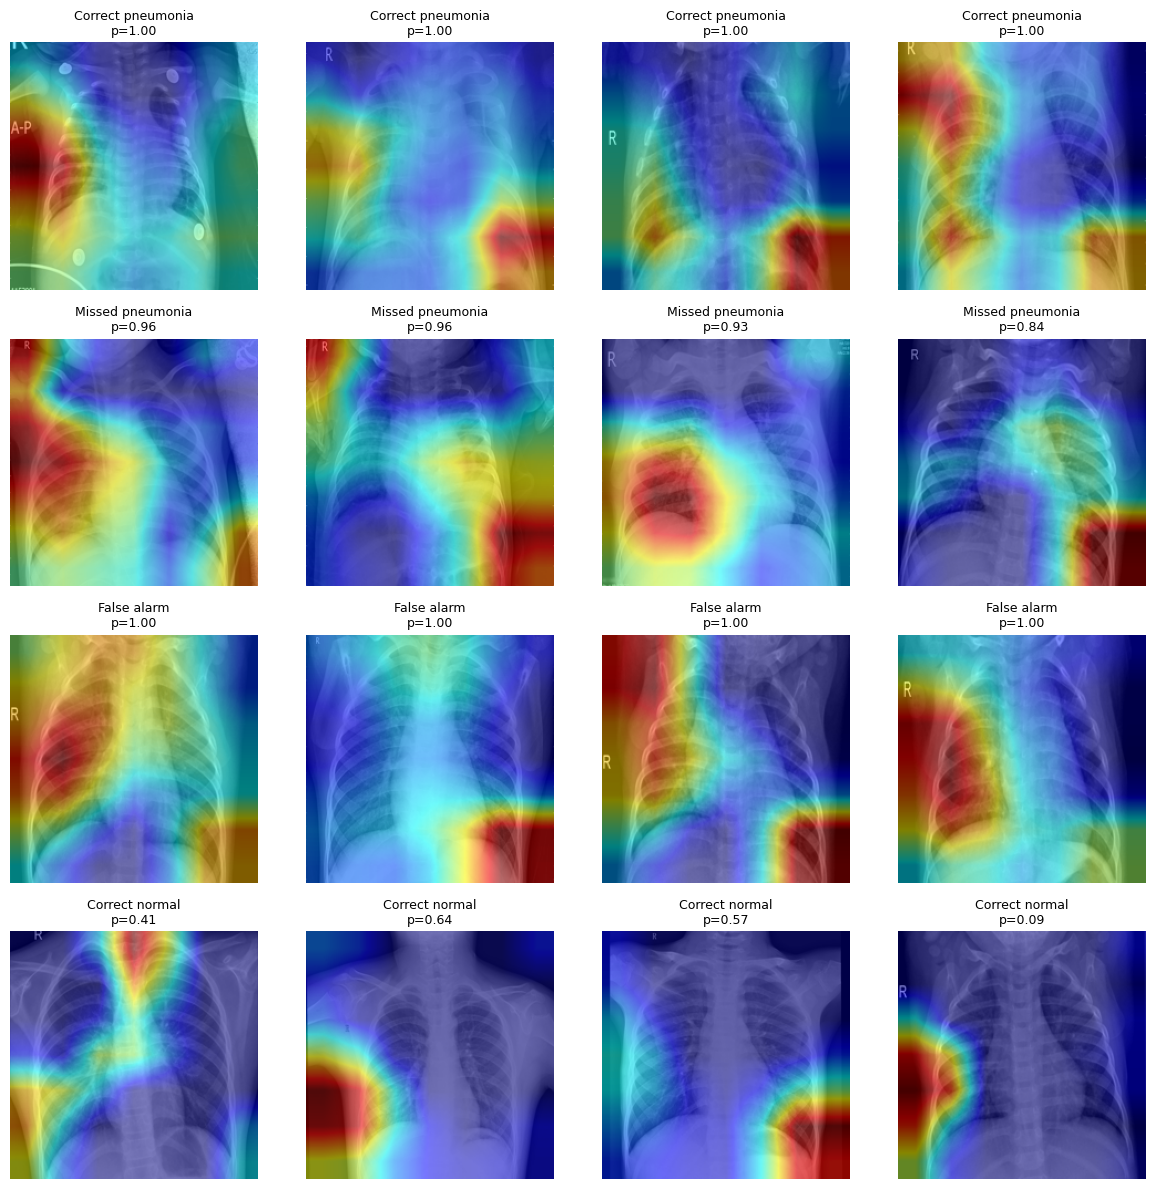

In [14]:

!pip -q install grad-cam

import matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

cam = GradCAM(model=model, target_layers=[model.layer4[-1]])

def cam_for(path):
    pil = Image.open(path).convert("L")
    x = eval_tf(pil).unsqueeze(0).to(device)

    g = cam(
        input_tensor=x,
        targets=[ClassifierOutputTarget(1)]
    )[0]

    base = np.array(
        pil.resize((224, 224)).convert("RGB")
    ).astype(np.float32) / 255.0

    return show_cam_on_image(base, g, use_rgb=True)


paths_t = [p for p, _ in test_items]
rng = np.random.default_rng(SEED)

groups = {
    "Correct pneumonia": np.where((yt == 1) & (pred_t == 1))[0],
    "Missed pneumonia": np.where((yt == 1) & (pred_t == 0))[0],
    "False alarm": np.where((yt == 0) & (pred_t == 1))[0],
    "Correct normal": np.where((yt == 0) & (pred_t == 0))[0],
}

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for r, (name, idxs) in enumerate(groups.items()):
    pick = rng.choice(
        idxs,
        size=min(4, len(idxs)),
        replace=False
    )

    for c in range(4):
        ax = axes[r, c]
        ax.axis("off")

        if c < len(pick):
            ax.imshow(cam_for(paths_t[pick[c]]))
            ax.set_title(
                f"{name}\np={pt[pick[c]]:.2f}",
                fontsize=9
            )

plt.tight_layout()
plt.savefig("gradcam.png", dpi=150)
plt.show()


In [15]:
def border_share(path, m=0.15):
    pil = Image.open(path).convert("L")
    x = eval_tf(pil).unsqueeze(0).to(device)
    g = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)])[0]
    h, w = g.shape; b = int(h * m)
    return 1 - g[b:h-b, b:w-b].sum() / g.sum()

rng = np.random.default_rng(0)
for name, idxs in groups.items():
    pick = rng.choice(idxs, size=min(80, len(idxs)), replace=False)
    shares = [border_share(paths_t[i]) for i in pick]
    print(f"{name:18s} border share: {np.mean(shares):.2f}")

Correct pneumonia  border share: 0.53
Missed pneumonia   border share: 0.49
False alarm        border share: 0.51


/tmp/ipykernel_47/781436656.py:6: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - g[b:h-b, b:w-b].sum() / g.sum()


Correct normal     border share: nan


In [16]:
import json
json.dump({"threshold": THRESHOLD}, open("threshold.json", "w"))
print(open("threshold.json").read())
print(os.listdir("."))

{"threshold": 0.9860923886299133}
['threshold.json', '.virtual_documents', 'gradcam.png', 'best_model.pt']
